# HW2

In [1]:
import numpy as np
from scipy import stats
import matplotlib.pyplot as plt

## Problem 1

As shown from the simulation below, rolling seven is more probable than rolling snake eyes.

The probability ratio is

$$
\frac{P(7)}{P(2)} = \frac{6}{1} = 6.
$$

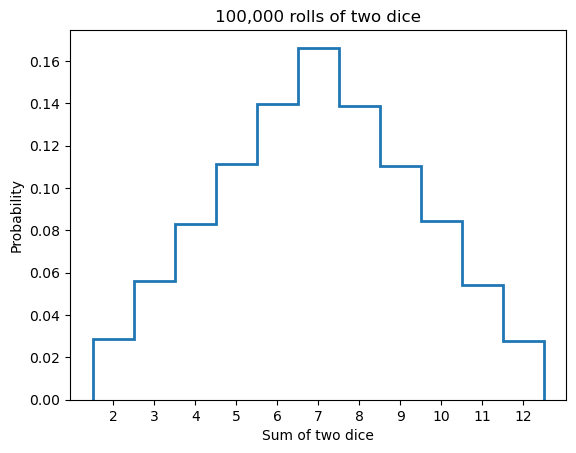

In [2]:
N = 100000
d1 = stats.randint.rvs(1, 7, size=N)
d2 = stats.randint.rvs(1, 7, size=N)
d = d1 + d2

fig, ax = plt.subplots()
ax.hist(
    d,
    bins=np.arange(1.5, 13.5, 1),
    histtype="step",
    linewidth=2,
    density=True,
)
ax.set(
    xlabel="Sum of two dice",
    ylabel="Probability",
    title=f"{N:,} rolls of two dice",
    xticks=range(2, 13),
)
plt.show()

## Problem 2

### Analytical Solution: Convolution of Two Dice

Let $X$ and $Y$ be two independent random variables representing the outcomes of two fair six-sided dice.

Their probability mass functions are

$$
p_X(x)=p_Y(x)=
\begin{cases}
\frac{1}{6}, & x=1,2,\ldots,6,\\
0, & \text{otherwise}.
\end{cases}
$$

Define the sum $Z=X+Y$. By discrete convolution,

$$
p_Z(z)=(p_X*p_Y)(z)
=\sum_{x=-\infty}^{\infty}p_X(x)p_Y(z-x).
$$

Therefore,

$$
\boxed{
p_Z(z)=
\begin{cases}
\frac{z-1}{36}, & 2\le z\le 7,\\[4pt]
\frac{13-z}{36}, & 8\le z\le 12,\\[4pt]
0, & \text{otherwise}.
\end{cases}
}
$$

Equivalently,

$$
\boxed{
p_Z(z)=\frac{6-|z-7|}{36},
\qquad z=2,3,\ldots,12.
}
$$

Finally, we verify normalization:

$$
\sum_{z=2}^{12}p_Z(z)
=\frac{1+2+3+4+5+6+5+4+3+2+1}{36}
=\frac{36}{36}=1.
$$

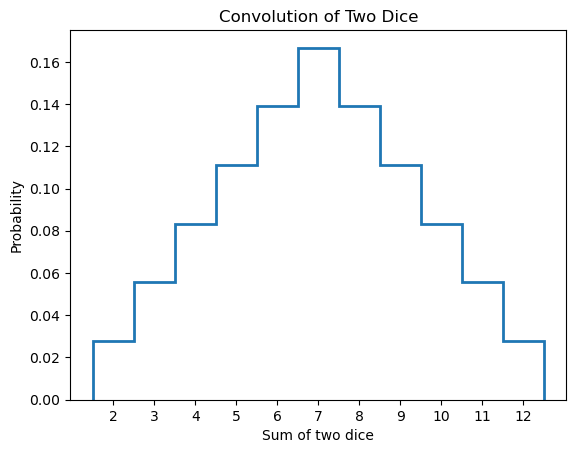

In [3]:
p = np.ones(6) / 6
p_sum = np.convolve(p, p, mode = 'full')
x_sum = np.arange(2, 13)

fig, ax = plt.subplots()

ax.stairs(
    p_sum,
    edges=np.arange(1.5, 13.5, 1),
    linewidth=2
)

ax.set(
    xlabel="Sum of two dice",
    ylabel="Probability",
    title="Convolution of Two Dice",
    xticks=x_sum
)

plt.show()

## Problem 3

### Mean and variance of two dice distribution

By the definition of mean and variance, we have:

In [4]:
mean = np.sum(x_sum * p_sum)
variance = np.sum((x_sum - mean)**2 * p_sum)

print("Mean:", mean)
print("Variance:", variance)

Mean: 6.999999999999998
Variance: 5.833333333333333


## Problem 4

### Distribution of the average of 10 dice

Convolve the distribution 9 times:

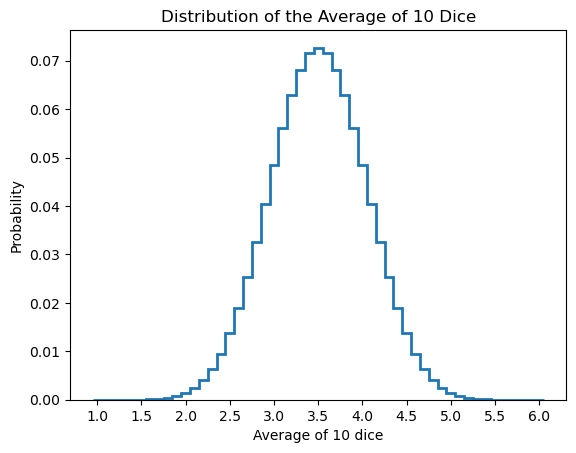

In [5]:
p = np.ones(6) / 6
p_10 = p.copy()
x_10 = np.arange(10, 61)
x_avg = x_10 / 10

for _ in range(9):
    p_10 = np.convolve(p_10, p, mode = 'full')

fig, ax = plt.subplots()

ax.stairs(
    p_10,
    edges=np.arange(9.5, 61.5) / 10,
    linewidth=2
)

ax.set(
    xlabel="Average of 10 dice",
    ylabel="Probability",
    title="Distribution of the Average of 10 Dice",
    xticks=np.arange(1, 6.1, 0.5)
)

plt.show()

As we can see from the distribution above, the average of 10 dice already resembles a Gaussian distribution, although it is not exactly Gaussian.

As the number of dice increases, the appropriately standardized distribution approaches a Gaussian distribution. This is a consequence of the **Central Limit Theorem (CLT)**, which states:

Let $X_1,X_2,\ldots,X_n$ be independent and identically distributed random variables with finite mean $\mu$ and variance $\sigma^2$. Define their sample mean as

$$
\bar X_n=\frac{1}{n}\sum_{i=1}^{n}X_i.
$$

Then, as $n\to\infty$,

$$
\boxed{
\frac{\bar X_n-\mu}{\sigma/\sqrt{n}}
\xrightarrow{d}\mathcal N(0,1)
}
$$


Equivalently, for sufficiently large $n$,

$$
\boxed{
\bar X_n\approx\mathcal N\left(\mu,\frac{\sigma^2}{n}\right).
}
$$

For a fair six-sided die,

$$
\mu=\frac72,\qquad \sigma^2=\frac{35}{12}.
$$

Therefore, the average of $n$ independent dice approximately follows

$$
\boxed{
\bar X_n\approx\mathcal N\left(\frac72,\frac{35}{12n}\right).
}
$$

## Problem 5

Let $X$ and $Y$ be independent Gaussian random variables:

$$
X\sim\mathcal{N}(\mu_X,\sigma_X^2),
\qquad
Y\sim\mathcal{N}(\mu_Y,\sigma_Y^2).
$$

The probability density of their sum $Z=X+Y$ is the convolution

$$
f_Z(z)=\int_{-\infty}^{\infty}f_X(x)f_Y(z-x)\,dx
$$

$$
=\frac{1}{2\pi\sigma_X\sigma_Y}
\int_{-\infty}^{\infty}
\exp\left[
-\frac{(x-\mu_X)^2}{2\sigma_X^2}
-\frac{(z-x-\mu_Y)^2}{2\sigma_Y^2}
\right]dx.
$$

we obtain

$$
f_Z(z)=
\frac{1}{\sqrt{2\pi V}}
\exp\left[-\frac{(z-\mu_X-\mu_Y)^2}{2V}\right].
$$

This is a Gaussian density, so

$$
X+Y\sim\mathcal{N}
\left(\mu_X+\mu_Y,\sigma_X^2+\sigma_Y^2\right).
$$

Repeating this result for $N$ independent Gaussian variables, each with mean $\mu$ and variance $\sigma^2$, gives

$$
S=\sum_{i=1}^{N}X_i
\sim\mathcal{N}(N\mu,N\sigma^2).
$$

The average $A=S/N$ is also Gaussian because multiplying a Gaussian variable by a constant preserves its Gaussian shape. Its mean and variance are

$$
\mathbb{E}[A]=\frac{N\mu}{N}=\mu,
\qquad
\operatorname{Var}(A)=\frac{N\sigma^2}{N^2}
=\frac{\sigma^2}{N}.
$$

Therefore,

$$
\boxed{\sigma_S=\sqrt{N}\,\sigma},
\qquad
\boxed{\sigma_A=\frac{\sigma}{\sqrt{N}}}.
$$

Averaging a steady signal over a longer time reduces the uncertainty because independent random noise tends to cancel out. For $N$ measurements,

$$
\sigma_{\text{average}}=\frac{\sigma}{\sqrt{N}}.
$$

For an integrated signal, the total signal grows as $N$, while its uncertainty grows only as $\sqrt{N}$. The signal therefore becomes easier to distinguish from the noise.

Error propagation means finding the uncertainty of a calculated result from the uncertainties of the measurements. When adding independent Gaussian measurements, their variances add:

$$
\sigma_{\text{sum}}=\sqrt{\sigma_1^2+\sigma_2^2}.
$$

This is the uncertainty rule used in previous classes.